# Dendritic ANN nonlinearities on CIFAR-10 (Colab)

Runs control 1 (homogeneous type) and the per-dendrite ratio sweep on CIFAR-10 with a GPU.
The dataset is downloaded to this Colab machine only; nothing lands on your laptop except the
small results zip at the end.

**Before running:** Runtime > Change runtime type > GPU (a T4 is fine). Then run the cells top to bottom.
Free Colab sessions can time out; the sweep skips finished runs, so just re-run the cells. Mounting
Google Drive (optional cell below) keeps the results across sessions.

In [19]:
!nvidia-smi -L
import torch
print("cuda available:", torch.cuda.is_available())

GPU 0: Tesla T4 (UUID: GPU-bd791d7d-6f34-34fc-6e14-1631a5a2fc19)
cuda available: True


## 1. Get the code
Clones the `bio-tuning` branch. Re-running this cell is safe.

In [20]:
%cd /content
![ -d NEU231_Final_Project ] || git clone -b bio-tuning https://github.com/HillaryKchao/NEU231_Final_Project.git
%cd /content/NEU231_Final_Project
!git pull -q
!pip install -q -r requirements.txt

/content
/content/NEU231_Final_Project


## 2. Where to keep results
Results go to your Google Drive by default (survives a session timeout); set `USE_DRIVE = False` to keep them on this machine only.
Otherwise they stay on this machine until you download the zip at the end.

In [21]:
import os
USE_DRIVE = True
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUT = "/content/drive/MyDrive/neu231/results"
else:
    OUT = "/content/NEU231_Final_Project/results"
os.makedirs(OUT, exist_ok=True)
os.environ["OUT"] = OUT          # the shell cells below read $OUT
os.environ["DATASET"] = "cifar10"
print("results go to", OUT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
results go to /content/drive/MyDrive/neu231/results


In [22]:
grid = """ca|--ca-thresh 0.1
ca|--ca-thresh 0.0
v1|--ca-thresh 0.3
branch --mix 12:3:1|--ca-thresh 0.3
branch --mix 1:1:1|--ca-thresh 0.3
branch --mix 1:3:12|--ca-thresh 0.3
"""
open("grid_thr.txt", "w").write(grid)
!GRID=grid_thr.txt DATASET=cifar10 OUT=$OUT bash sweep_constants.sh

=== seed 1 | 16 dends x 256 somata | ca --ca-thresh 0.1 ===
dANN-local | ca dendrites | cifar10 | 1 layer(s) | 16 dends x 256 somata | 207,626 trainable params | cuda
images: train 45,000 | val 5,000 | test 10,000
epoch   1/50  train loss 1.9407 acc 0.3024 | val loss 1.7593 acc 0.3916 | 3.1s
epoch   2/50  train loss 1.6754 acc 0.4067 | val loss 1.6159 acc 0.4372 | 2.9s
epoch   3/50  train loss 1.5643 acc 0.4432 | val loss 1.5259 acc 0.4586 | 2.9s
epoch   4/50  train loss 1.4749 acc 0.4775 | val loss 1.4627 acc 0.4866 | 2.8s
epoch   5/50  train loss 1.4102 acc 0.4981 | val loss 1.4269 acc 0.4892 | 3.0s
epoch   6/50  train loss 1.3626 acc 0.5123 | val loss 1.3888 acc 0.5074 | 2.9s
epoch   7/50  train loss 1.3180 acc 0.5294 | val loss 1.3682 acc 0.5080 | 3.0s
epoch   8/50  train loss 1.2836 acc 0.5426 | val loss 1.3351 acc 0.5168 | 2.9s
epoch   9/50  train loss 1.2488 acc 0.5551 | val loss 1.3094 acc 0.5312 | 2.9s
epoch  10/50  train loss 1.2209 acc 0.5626 | val loss 1.2778 acc 0.5514 | 2

## 3. Smoke test (a few minutes the first time)
One epoch on 5,000 training images (40 gradient steps). The first run also downloads CIFAR-10
to this machine's `data/` folder, which can take several minutes on a slow mirror; the training
itself takes about a second. Expect `cuda` in the first line and a test accuracy around 20%
(chance is 10%; the full 50-epoch runs reach the mid-50s).

In [ ]:
!python base_model.py --dataset cifar10 --dends 16 --soma 256 --epochs 1 --train-subset 5000 --out /tmp/smoke

100% 170M/170M [08:32<00:00, 333kB/s]
dANN-local | leaky dendrites | cifar10 | 1 layer(s) | 16 dends x 256 somata | 207,626 trainable params | cuda
images: train 5,000 | val 5,000 | test 10,000  (TRAIN SUBSET)
epoch   1/1  train loss 2.2809 acc 0.1590 | val loss 2.2413 acc 0.1978 | 0.8s

Test acc: 0.2003 | Test loss: 2.2409
Saved /tmp/smoke/dann_local_cifar10_L1_d16_s256_seed1_n5000.json and .pt


## 4. Control 1 on CIFAR-10
LeakyReLU baseline, supra-only, sub-only, Ca-only and V1 mixed; seeds 1-3 at 16 x 256, 50 epochs each.
Roughly 2 hours on a T4. Already-finished runs are skipped, so re-run after a timeout.

In [ ]:
!DATASET=cifar10 OUT=$OUT bash sweep_controls.sh

skip dann_local_cifar10_L1_d16_s256_seed1 (already done)
skip dann_supra_local_cifar10_L1_d16_s256_seed1 (already done)
skip dann_sub_local_cifar10_L1_d16_s256_seed1 (already done)
skip dann_ca_local_cifar10_L1_d16_s256_seed1 (already done)
skip dann_v1_local_cifar10_L1_d16_s256_seed1 (already done)
skip dann_local_cifar10_L1_d16_s256_seed2 (already done)
skip dann_supra_local_cifar10_L1_d16_s256_seed2 (already done)
skip dann_sub_local_cifar10_L1_d16_s256_seed2 (already done)
skip dann_ca_local_cifar10_L1_d16_s256_seed2 (already done)
skip dann_v1_local_cifar10_L1_d16_s256_seed2 (already done)
skip dann_local_cifar10_L1_d16_s256_seed3 (already done)
skip dann_supra_local_cifar10_L1_d16_s256_seed3 (already done)
skip dann_sub_local_cifar10_L1_d16_s256_seed3 (already done)
skip dann_ca_local_cifar10_L1_d16_s256_seed3 (already done)
skip dann_v1_local_cifar10_L1_d16_s256_seed3 (already done)

Done. Next:
  python plot_results.py --results /content/drive/MyDrive/neu231/results
  python an

## 5. Ratio sweep on CIFAR-10
One nonlinearity per dendrite at 12:3:1 (biological), 1:1:1 and 1:3:12; seeds 1-3. About an hour.

In [ ]:
!DATASET=cifar10 NONLINS=branch OUT=$OUT bash sweep_controls.sh

skip dann_branch12-3-1_local_cifar10_L1_d16_s256_seed1 (already done)
skip dann_branch1-1-1_local_cifar10_L1_d16_s256_seed1 (already done)
skip dann_branch1-3-12_local_cifar10_L1_d16_s256_seed1 (already done)
skip dann_branch12-3-1_local_cifar10_L1_d16_s256_seed2 (already done)
skip dann_branch1-1-1_local_cifar10_L1_d16_s256_seed2 (already done)
skip dann_branch1-3-12_local_cifar10_L1_d16_s256_seed2 (already done)
skip dann_branch12-3-1_local_cifar10_L1_d16_s256_seed3 (already done)
skip dann_branch1-1-1_local_cifar10_L1_d16_s256_seed3 (already done)
skip dann_branch1-3-12_local_cifar10_L1_d16_s256_seed3 (already done)

Done. Next:
  python plot_results.py --results /content/drive/MyDrive/neu231/results
  python analyze_v1.py /content/drive/MyDrive/neu231/results/dann_v1_local_cifar10_L1_d16_s256_seed3 --data-dir data


## 5b. Stage 1: constants grid and the Ca gate (1 seed, about 2.5 h)
Varies the fixed constants of the biological nonlinearities (passive leak, Ca threshold, saturation,
exponent) and trains the apical Ca-gate model, one seed each. See `sweep_constants.sh` for the grid.

In [23]:
!DATASET=cifar10 OUT=$OUT bash sweep_constants.sh

=== seed 1 | 16 dends x 256 somata | supra --supra-p 1.5 ===
skip dann_supra_local_cifar10_L1_d16_s256_p1.5_seed1 (already done)
=== seed 1 | 16 dends x 256 somata | supra --leak 0.1 ===
skip dann_supra_local_cifar10_L1_d16_s256_leak0.1_seed1 (already done)
=== seed 1 | 16 dends x 256 somata | supra --supra-p 1.5 --leak 0.1 ===
skip dann_supra_local_cifar10_L1_d16_s256_p1.5_leak0.1_seed1 (already done)
=== seed 1 | 16 dends x 256 somata | sub --sub-sat 2 ===
skip dann_sub_local_cifar10_L1_d16_s256_sat2_seed1 (already done)
=== seed 1 | 16 dends x 256 somata | sub --sub-sat 4 ===
skip dann_sub_local_cifar10_L1_d16_s256_sat4_seed1 (already done)
=== seed 1 | 16 dends x 256 somata | sub --leak 0.1 ===
skip dann_sub_local_cifar10_L1_d16_s256_leak0.1_seed1 (already done)
=== seed 1 | 16 dends x 256 somata | sub --sub-sat 2 --leak 0.1 ===
skip dann_sub_local_cifar10_L1_d16_s256_sat2_leak0.1_seed1 (already done)
=== seed 1 | 16 dends x 256 somata | sub --sub-sat 4 --leak 0.1 ===
skip dann_sub

## 5c. Pick the winners on validation accuracy
Ranks every variant by validation accuracy (never test) and prints the winners as grid lines.

In [24]:
!python plot_results.py --results $OUT --dataset cifar10 --out figures/cifar10 --select best-val 2>&1 | sed -n '/Constants sweep/,$p'

Constants sweep: variants ranked by VALIDATION accuracy (%) on the seeds they share ('matched'); test shown for reference
dataset   size                   model                variant                    seeds  matched         val acc        test acc  pick
cifar10   16 dends x 256 somata  supra-only           p1.5_leak0.1                   3    57.16   56.89 +/- 0.43   56.72 +/- 0.31  <-
cifar10   16 dends x 256 somata  supra-only           leak0.1                        1    56.42   56.42 +/- 0.00   56.22 +/- 0.00  
cifar10   16 dends x 256 somata  supra-only           p1.5                           1    56.42   56.42 +/- 0.00   56.73 +/- 0.00  
cifar10   16 dends x 256 somata  supra-only           (defaults)                     3    56.14   55.72 +/- 0.61   56.23 +/- 0.17  
cifar10   16 dends x 256 somata  sub-only             (defaults)                     3    57.88   56.77 +/- 1.03   55.89 +/- 0.83  <-
cifar10   16 dends x 256 somata  sub-only             leak0.1                   

## 5d. Stage 2: winners with seeds 2 and 3 (about 2 h)
Reads the selected variants from `constants_sweep.csv` and reruns them with more seeds.

In [25]:
import csv
rows = list(csv.DictReader(open("figures/cifar10/constants_sweep.csv")))
winners = sorted({r["grid_line"] for r in rows if r["selected"] == "yes"})
open("grid_stage2.txt", "w").write("\n".join(winners) + "\n")
print("\n".join(winners))
!SEEDS="2 3" GRID=grid_stage2.txt DATASET=cifar10 OUT=$OUT bash sweep_constants.sh

branch --mix 12:3:1|--ca-thresh 0.3
branch --mix 1:1:1|
branch --mix 1:3:12|--ca-thresh 0.3
ca|--ca-thresh 0
gate|
sub|
supra|--supra-p 1.5 --leak 0.1
v1|
=== seed 2 | 16 dends x 256 somata | branch --mix 12:3:1 --ca-thresh 0.3 ===
dANN-local | branch dendrites | cifar10 | 1 layer(s) | 16 dends x 256 somata | 207,626 trainable params | cuda
images: train 45,000 | val 5,000 | test 10,000
epoch   1/50  train loss 1.9540 acc 0.3062 | val loss 1.8107 acc 0.3682 | 3.4s
epoch   2/50  train loss 1.7151 acc 0.3963 | val loss 1.6692 acc 0.4118 | 3.1s
epoch   3/50  train loss 1.5995 acc 0.4352 | val loss 1.6205 acc 0.4246 | 3.0s
epoch   4/50  train loss 1.5288 acc 0.4593 | val loss 1.5658 acc 0.4472 | 3.0s
epoch   5/50  train loss 1.4820 acc 0.4759 | val loss 1.4995 acc 0.4724 | 3.0s
epoch   6/50  train loss 1.4435 acc 0.4877 | val loss 1.4789 acc 0.4680 | 3.1s
epoch   7/50  train loss 1.4077 acc 0.5000 | val loss 1.4524 acc 0.4806 | 3.1s
epoch   8/50  train loss 1.3796 acc 0.5103 | val loss 1.4

## 6. Figures and tables
Writes figures 1-10 and the CSVs for CIFAR-10 into `figures/cifar10/`, using the validation-selected
constants for the comparison figures, then inspects the V1 mixed model and the Ca-gate model.

In [26]:
!python plot_results.py --results $OUT --dataset cifar10 --out figures/cifar10 --select best-val
!python analyze_v1.py $OUT/dann_v1_local_cifar10_L1_d16_s256_seed1 --data-dir data --out figures/cifar10
!ls $OUT/dann_gate_local_cifar10_L1_d16_s256_seed1.json 2>/dev/null && python analyze_v1.py $OUT/dann_gate_local_cifar10_L1_d16_s256_seed1 --data-dir data --out figures/cifar10

Loaded 65 runs = 33 model configurations
Variant selection for figures 7-8 and the control tables: best-val
  wrote figures/cifar10/1_paper_comparison.png
  wrote figures/cifar10/2_size_sweep.png
  skipping 3_dendrites_per_soma.png: need >= 2 dendrite counts at one soma count
  wrote figures/cifar10/4_learning_curves.png
  wrote figures/cifar10/7_control_homogeneous.png
  wrote figures/cifar10/8_ratio_sweep.png
  wrote figures/cifar10/9_constants_sweep.png
  wrote figures/cifar10/summary.csv

Best model vs paper Table 1 (test accuracy, %)
dataset   model                               best size              seeds           yours           paper    diff  verdict
cifar10   dANN-LRF                            16 dends x 256 somata      3  57.43 +/- 0.93  56.97 +/- 0.98   +0.46  matches paper
cifar10   dANN-LRF supra-only                 16 dends x 256 somata      3  56.23 +/- 0.17  56.97 +/- 0.98   -0.74  matches paper
cifar10   dANN-LRF supra-only [leak0.1]       16 dends x 256 somata    

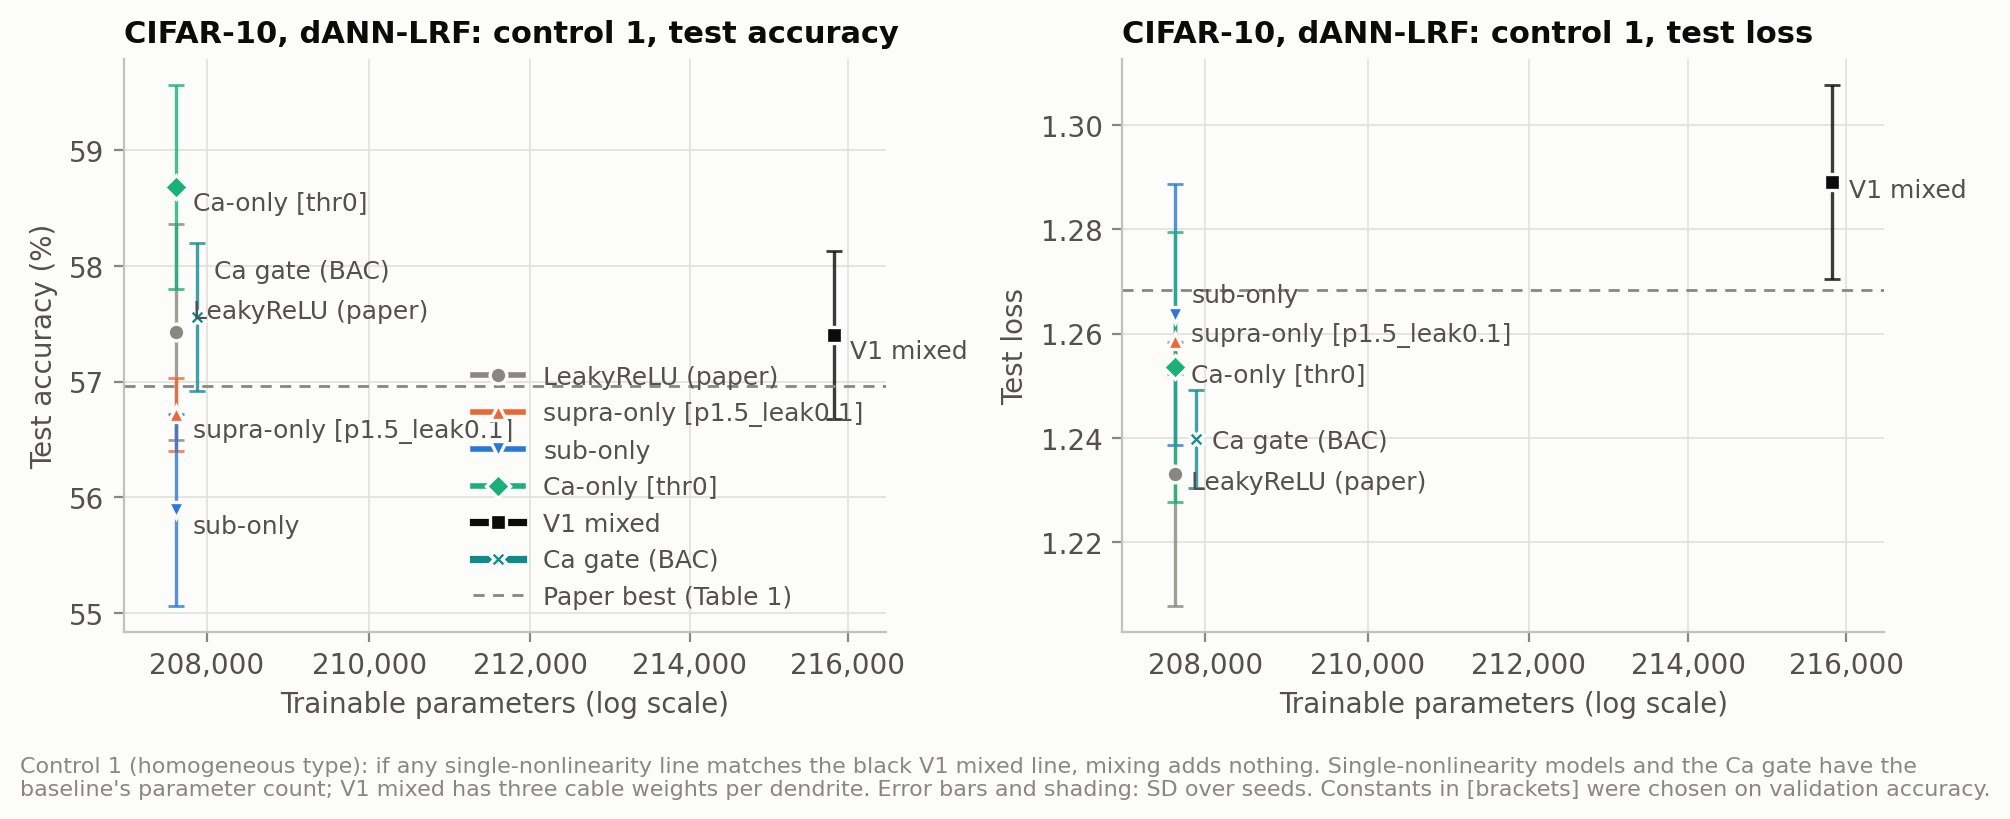

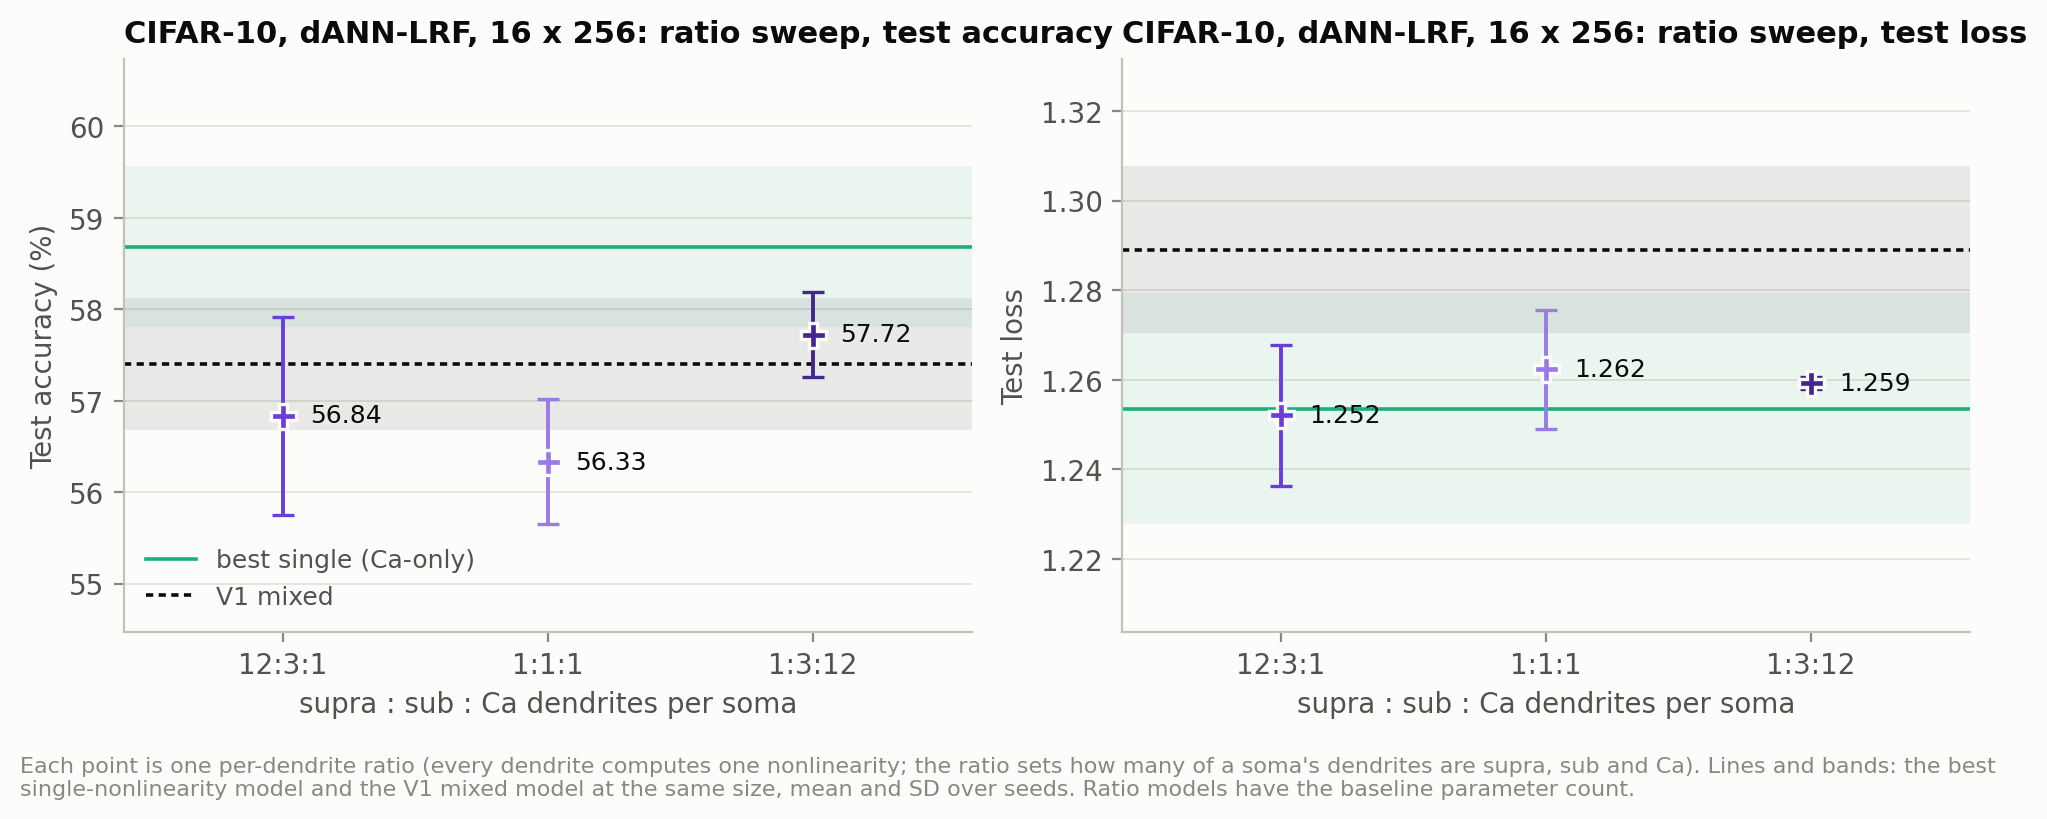

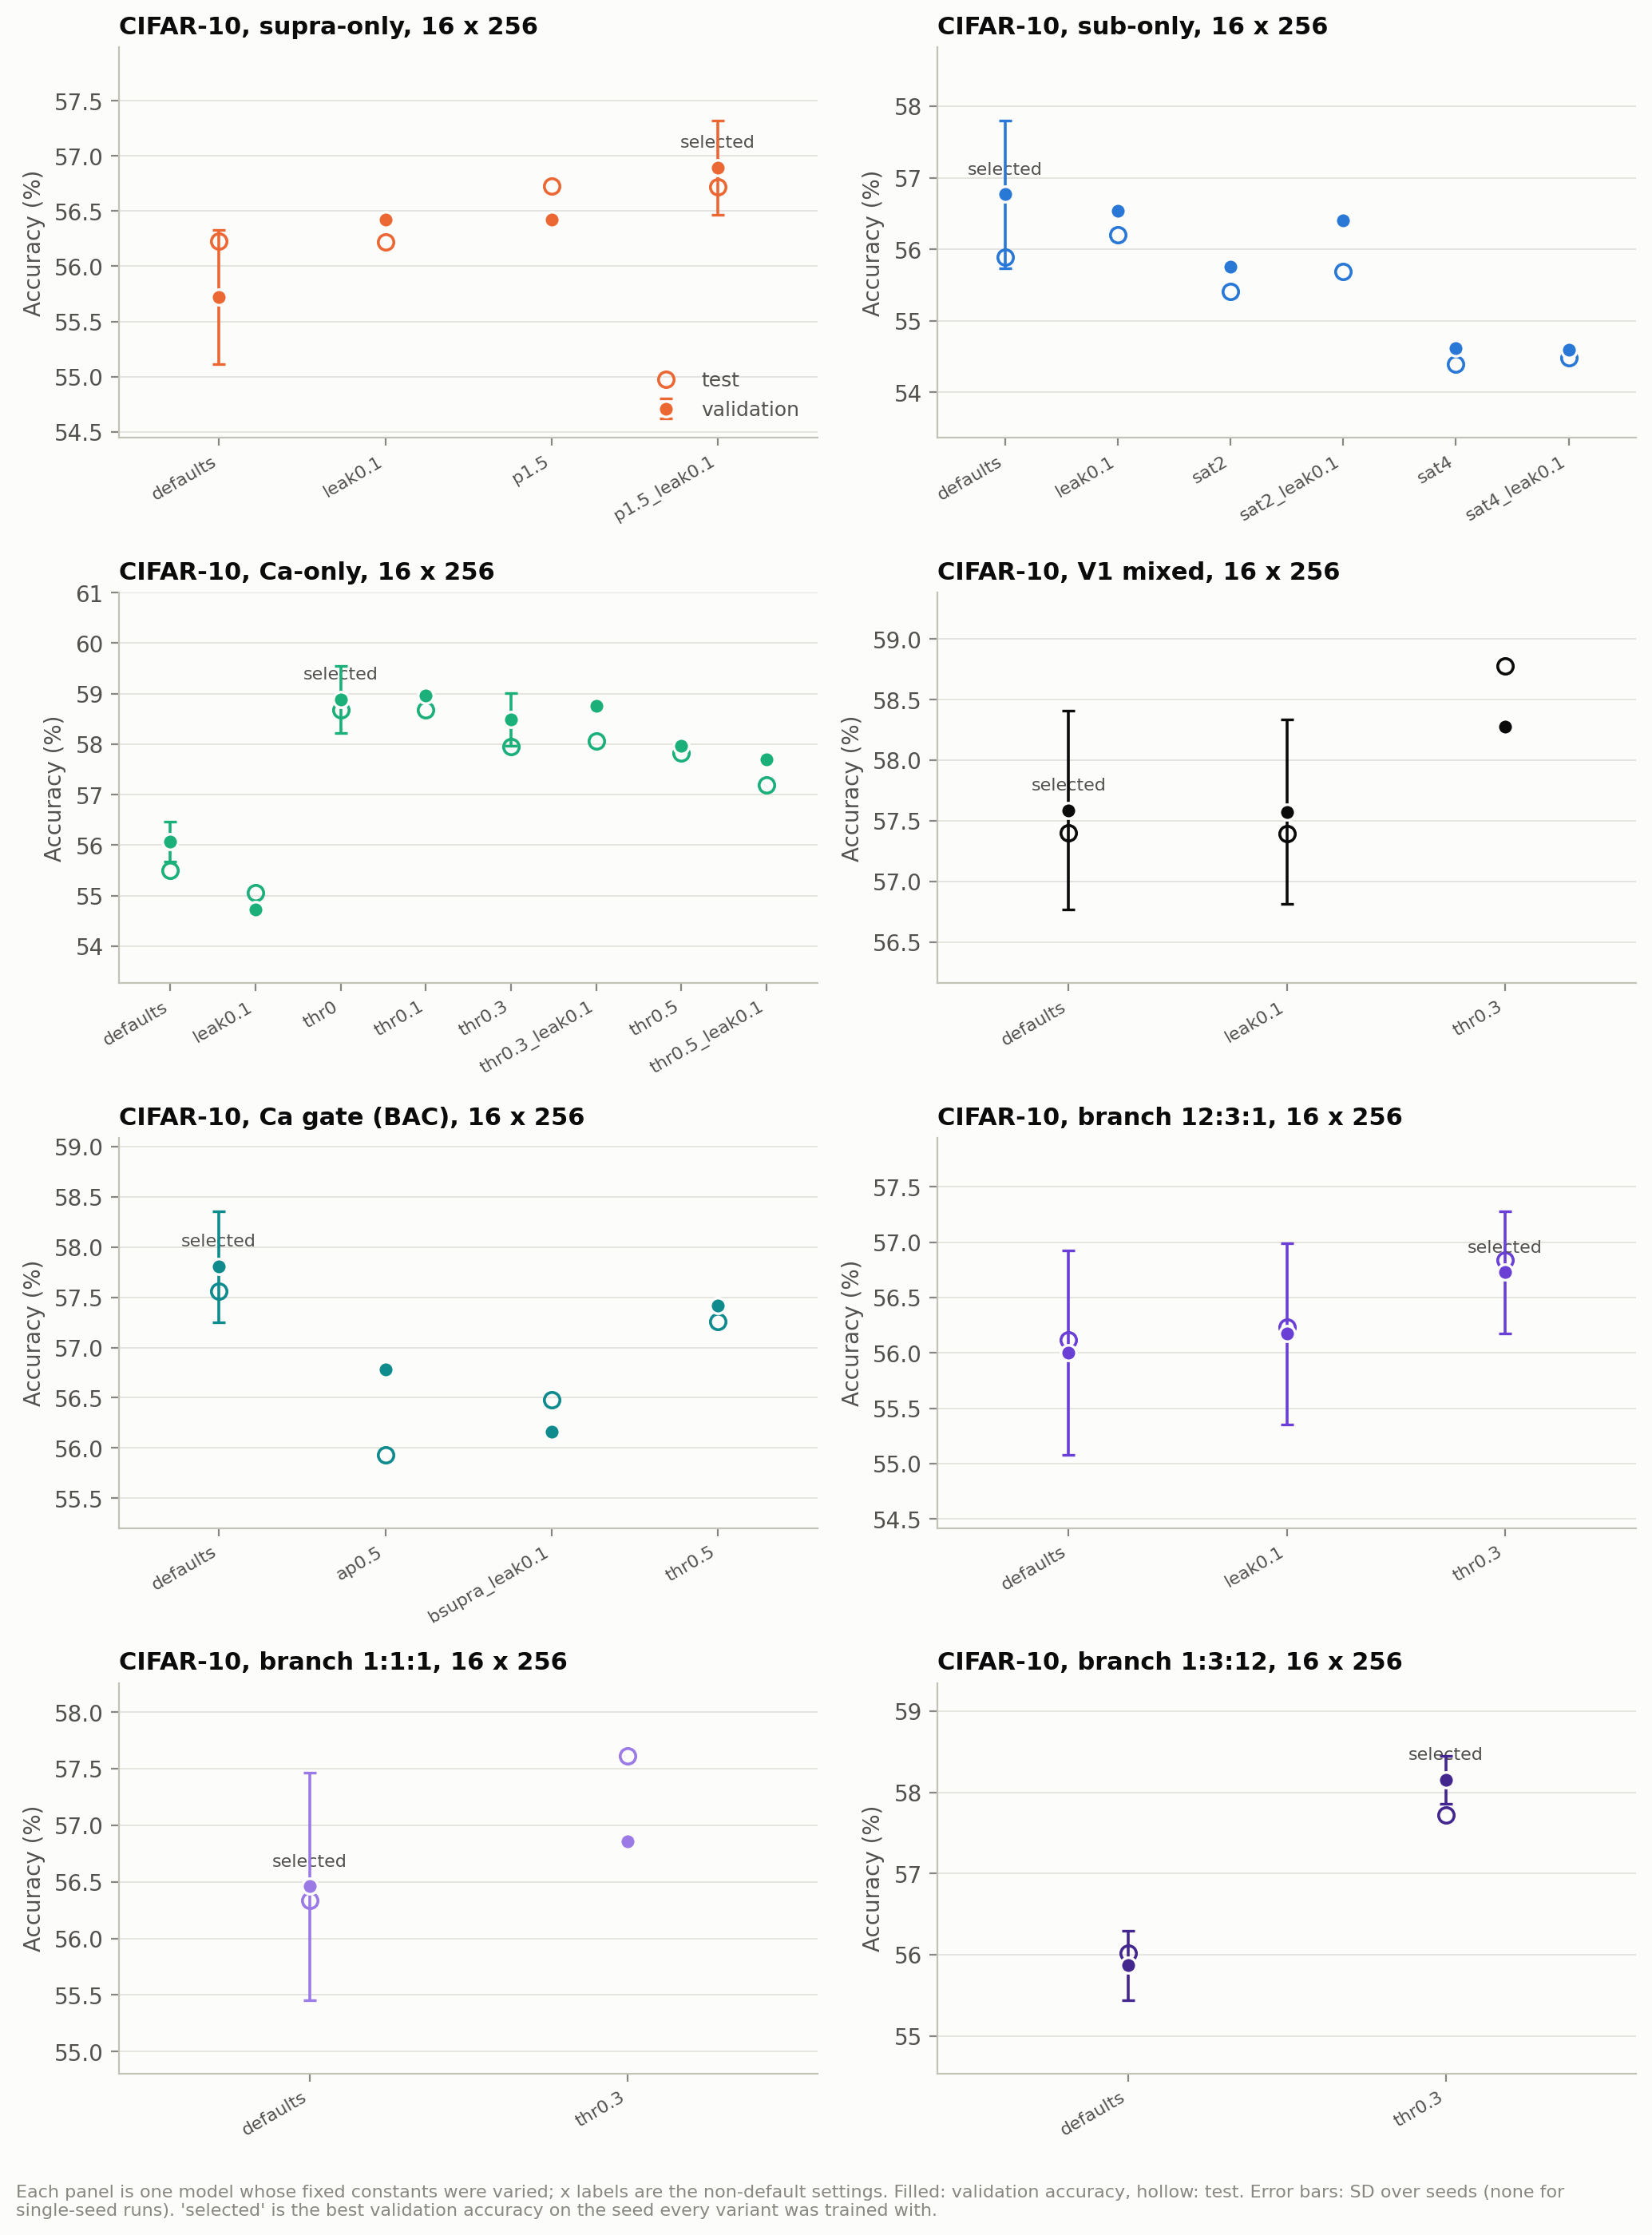

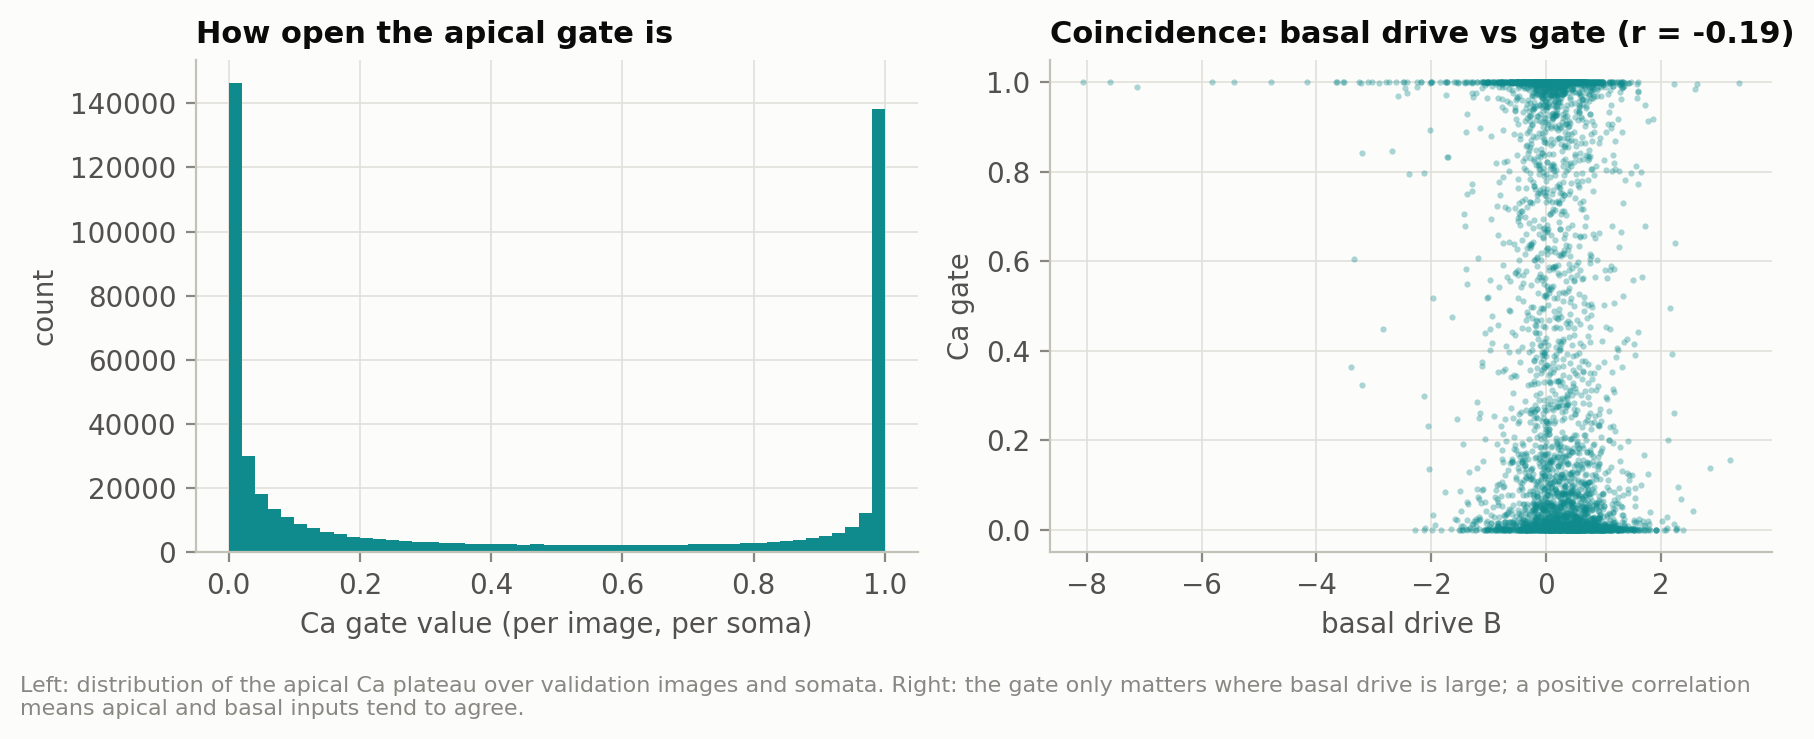

In [27]:
import os
from IPython.display import Image, display
for f in ["7_control_homogeneous.png", "8_ratio_sweep.png", "9_constants_sweep.png", "10_gate_activity.png"]:
    if os.path.exists(f"figures/cifar10/{f}"):
        display(Image(f"figures/cifar10/{f}"))

## 7. Bring the results home
Zips the result JSONs (the numbers), the CIFAR-10 figures and the log, and downloads it.
The `.pt` weight files are left out (about 1 MB each); set `INCLUDE_WEIGHTS = True` if you want them.
If the runtime restarted since the sweeps ran, re-run cells 1 and 2 first so `OUT` is defined again.
Locally, unzip into the repo and run `python plot_results.py --results results --dataset cifar10 --out figures/cifar10`
to regenerate the figures from the JSONs.

In [28]:
# Plain Python paths, so this works after a runtime restart (re-run cells 1 and 2 first).
import glob, os, zipfile
INCLUDE_WEIGHTS = False
REPO = "/content/NEU231_Final_Project"
results = sorted(glob.glob(f"{OUT}/*cifar10*" if INCLUDE_WEIGHTS else f"{OUT}/*cifar10*.json"))
assert results, (f"no CIFAR-10 results in {OUT}. Re-run the setup cells (1 and 2); if still empty, "
                 "the VM was recycled and the sweeps must be re-run (use USE_DRIVE = True).")
figs = sorted(glob.glob(f"{REPO}/figures/cifar10/*"))
zip_path = "/content/results_cifar10.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for f in results:
        z.write(f, f"results/{os.path.basename(f)}")
    for f in figs:
        z.write(f, f"figures/cifar10/{os.path.basename(f)}")
    log = f"{REPO}/sweep_controls.log"
    if os.path.exists(log):
        z.write(log, "sweep_controls.log")
print(f"{len(results)} result files, {len(figs)} figures -> {zip_path} "
      f"({os.path.getsize(zip_path) / 1e6:.1f} MB)")
from google.colab import files
files.download(zip_path)

65 result files, 15 figures -> /content/results_cifar10.zip (5.4 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>